In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.io.sas.sas_constants import column_name_text_subheader_length
from joblib import Parallel, delayed
from scipy.linalg import bandwidth
from pymoo.util.nds.non_dominated_sorting import NonDominatedSorting

import src.preference.models as preference_models
from src.core.problem_lp import *
from src.core.problem_nlp import *
from src.optimization.normalization_utils import compute_obj_bounds_lp, compute_obj_bounds_nlp, extract_and_normalize_X
from src.optimization.solve_lp_scalarized import solve_beta_weighted_lp, solve_beta_weighted_lp_gurobi
from src.optimization.solve_nlp_scalarized import solve_beta_weighted_nlp
from src.sensitivity.shapley import shapley_values_kernel
from src.utils.utils import *
from src.utils.plotting import *
from src.sensitivity.sobol import *
from src.sensitivity.shapley import *
from src.sensitivity.utils import *
from src.utils.design_generator import generate_hypercube_samples, add_linearization_vars

plt.rcParams.update({
    "font.family": "Times New Roman",
    "mathtext.fontset": "cm",
    "font.size": 14,
    "axes.titlesize": 14,
    "axes.labelsize": 14,
    "xtick.labelsize": 16,
    "ytick.labelsize": 12,
    "legend.fontsize": 14,
})

In [2]:
def solve_normalized_problem_over_beta_parallel(solve_once, beta_samples, f_min, f_max, n_jobs=8):
    results = Parallel(n_jobs=n_jobs)(
        delayed(solve_once)(problem, beta, f_min, f_max)
        for beta in beta_samples
    )
    return results

In [3]:
# Preference setting
def gen_preferences(mu, Sigma, n_samples, rng):
    gp = preference_models.GaussianPreference(mean=mu, cov=Sigma, clip_nonnegative=True)
    betas = gp.sample(n=n_samples, rng=rng)
    return betas

In [4]:
mu, Sigma, n_samples, rng = np.array([1, 1, 1, 1]), 0.5 * np.eye(4), 1000, np.random.default_rng(42)
betas = gen_preferences(mu, Sigma, n_samples, rng)

In [5]:
# Case 1: Discrete case
problem = LP()
f_min, f_max = compute_obj_bounds_lp(problem)
# results = solve_normalized_problem_over_beta_parallel(solve_beta_weighted_lp, betas, f_min, f_max)
results = solve_normalized_problem_over_beta_parallel(solve_beta_weighted_lp_gurobi, betas, f_min, f_max)

print(f_min, f_max)


[ 0. 34.  0. 32.] [  23.  175. 1792.  160.]


In [6]:
# Table 1: Discrete optimal decisions and their empirical probabilities from the LP under preference uncertainty
import pandas as pd

var_names = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6']

X = np.array([[res['x_opt'][v] for v in var_names] for res in results])
unique_rows, counts = np.unique(X, axis=0, return_counts=True)
probabilities = counts / counts.sum()
df_discrete_X_unique = pd.DataFrame(unique_rows, columns=var_names)
df_discrete_X_unique['probability'] = probabilities
df_discrete_X_unique.sort_values("probability", ascending=False)

,x1,x2,x3,x4,x5,x6,probability
4,4.5,6.0,1.0,1.0,15.0,34.0,0.505
3,4.5,6.0,1.0,1.0,6.0,34.0,0.186
2,4.5,6.0,1.0,1.0,4.5,132.0,0.161
1,4.5,6.0,1.0,1.0,4.5,34.0,0.121
0,4.5,6.0,1.0,1.0,0.0,132.0,0.027


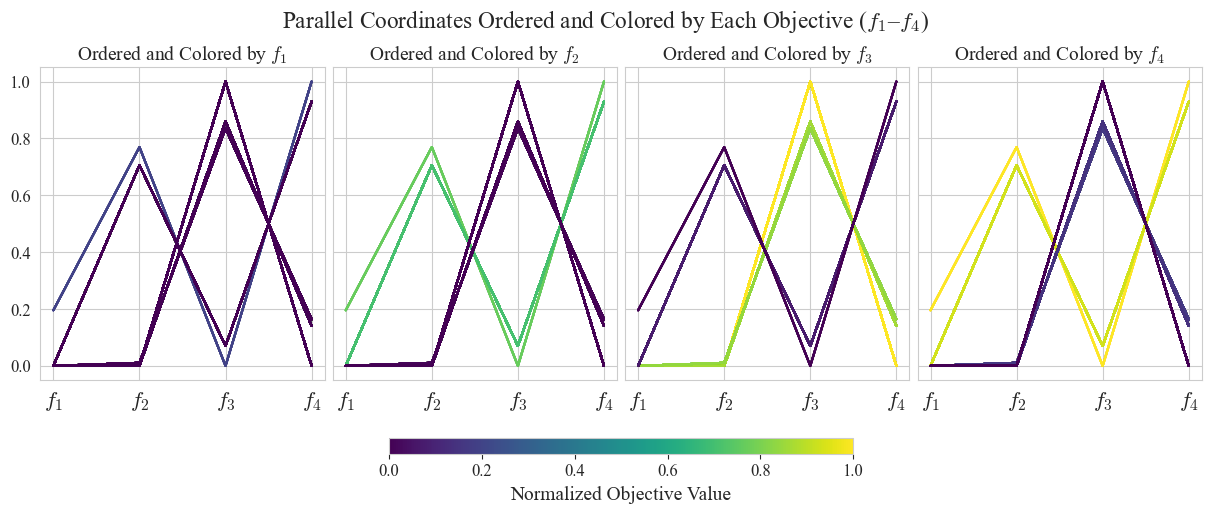

In [7]:
# Figure 5: Parallel coordinates plot of normalized objective values for Pareto-optimal solu-tions in Case Study 1 (discrete distribution)
f_norm = np.array([res['f_norm'] for res in results])
df_discrete_F = pd.DataFrame(f_norm, columns=["f1", "f2", "f3", "f4"])
p = parallel_coordinates_objectives(df_discrete_F)
# p.show()
p.savefig("../results/plots/preference_problem4_norm_parallel_coordinates.png", dpi=600)


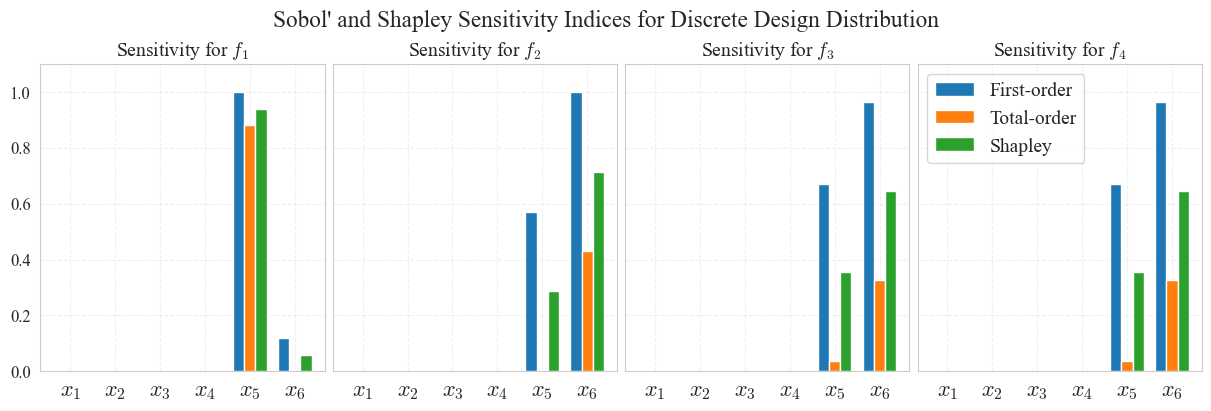

In [8]:
# Figure 6: Sobol' and Shapley sensitivity indices for discrete optimal decision solutions across the four objectives.
df_sobol_first_discrete = sobol_first_order_discrete(X, f_norm)
df_sobol_total_discrete = sobol_total_order_discrete(X, f_norm)
df_shapley_discrete = shapley_values_discrete(X, f_norm)
# df_sobol_first_discrete, df_sobol_total_discrete, df_shapley_discrete, df_shapley_discrete.sum()
p = histogram_sensitivity(df_sobol_first_discrete, df_sobol_total_discrete, df_shapley_discrete, title="Sobol' and Shapley Sensitivity Indices for Discrete Design Distribution")
# p.show()
p.savefig("../results/plots/preference_problem4_normalized_lp_sobol.png", dpi=600)

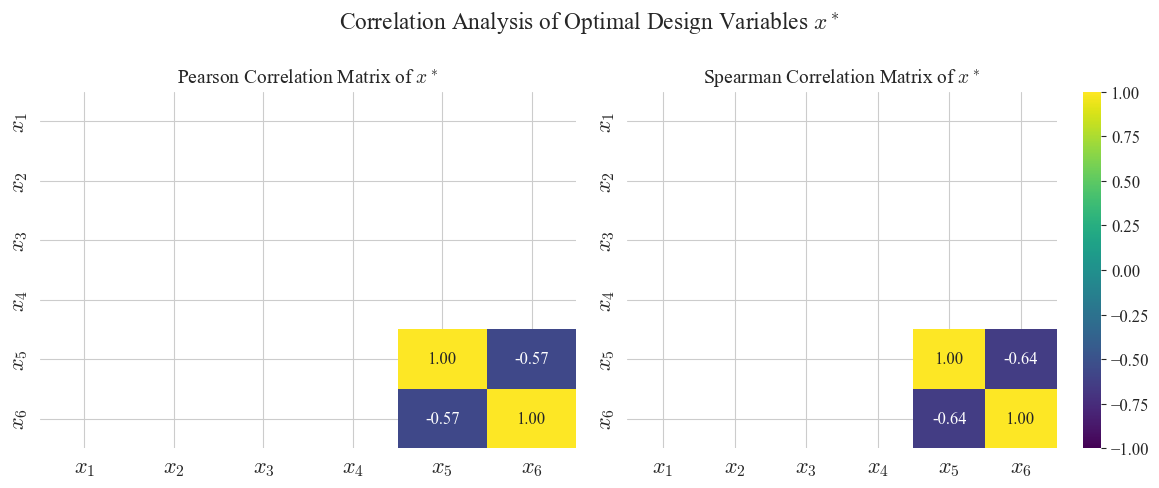

In [9]:
# Figure 7: Pearson and Spearman correlation matrices of the discrete design distribution.
df_discrete = pd.DataFrame(X, columns=[r"$x_1$", r"$x_2$", r"$x_3$", r"$x_4$", r"$x_5$", r"$x_6$"])
corr_pearson = df_discrete.corr()
corr_spearman = df_discrete.corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(corr_pearson, annot=True, fmt=".2f", annot_kws={"size": 12}, cmap="viridis", vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("Pearson Correlation Matrix of $x^*$")
axes[0].tick_params(axis='y', labelsize=16)

sns.heatmap(corr_spearman, annot=True, fmt=".2f", annot_kws={"size": 12}, cmap="viridis", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman Correlation Matrix of $x^*$")
axes[1].tick_params(axis='y', labelsize=16)
plt.suptitle(r"Correlation Analysis of Optimal Design Variables $x^*$")
plt.tight_layout()
# plt.show()
plt.savefig("../results/plots/preference_problem4_norm_t_star_dependence.png", dpi=600)

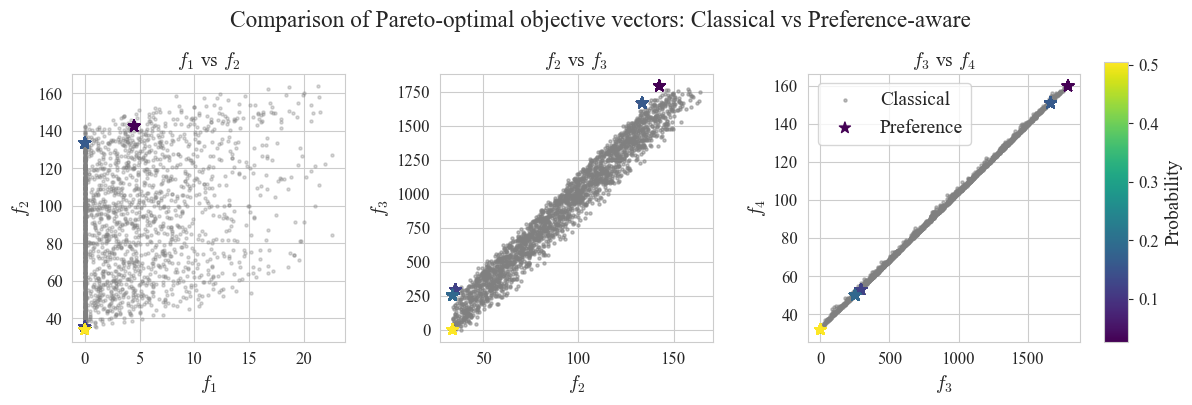

In [10]:
# Figure 8: Classical Pareto-optimal objective vectors (grey) vs. preference-aware solutions (colored by probability mass) for discrete optimal decision.

X, X_vars = generate_hypercube_samples(bounds=problem._bounds, n_samples=100000, exclude_vars=['x7', 'x8'])
X_full, X_vars_full = add_linearization_vars(X, X_vars)
X_dict = [{k: float(v) for k, v in zip(X_vars_full, row)}for row in X_full]
feas_mask = np.array([problem.is_feasible(x) for x in X_dict])
X_dict_feas = [x for x, ok in zip(X_dict, feas_mask) if ok]
obj_names = ["f1", "f2", "f3", "f4"]
F_dict = [problem.evaluate_objectives(x) for x in X_dict_feas]
F_mat  = np.array([[float(d[k]) for k in obj_names] for d in F_dict], dtype=float)

weights = np.array([1.0, 1.0, -1.0, 1.0], dtype=float)
nds = NonDominatedSorting()
pareto_idx = nds.do(F_mat * weights, only_non_dominated_front=True)

# X_pareto = [X_dict_feas[i] for i in pareto_idx]
F_classical = F_mat[pareto_idx]

p = scatter_preference_vs_classical(F_classical, results)
# p.show()
p.savefig("../results/plots/preference_problem4_comparison_moo_preference.png", dpi=600)

In [11]:
# Table 2: Frechet variance of the discrete optimal decision distribution under different pref-erence settings.

preferences_for_frechet_variance = [[np.array([1, 1, 1, 1]), 0.5 * np.eye(4), "Baseline"],
                                    [np.array([1, 1, 1, 1]), 0.1 * np.eye(4), "Low uncertainty"],
                                    [np.array([1, 1, 1, 1]), 1.0 * np.eye(4), "High uncertainty"],
                                    [np.array([1, 1, 3, 1]), 0.5 * np.eye(4), "Objective 3 emphasized"],
                                    [np.array([1, 1, 1, 3]), 0.5 * np.eye(4), "Objective 4 emphasized"]]

for p in preferences_for_frechet_variance:
    betas = gen_preferences(p[0], p[1], 1000, np.random.default_rng(42))
    results = solve_normalized_problem_over_beta_parallel(solve_beta_weighted_lp_gurobi, betas, f_min, f_max)
    X_raw, X_norm = extract_and_normalize_X(results, problem._bounds)
    print(f"{p[2]}: {frechet_variance(X_norm[:, :-2])}")


Baseline: 0.2719
Low uncertainty: 0.13020979
High uncertainty: 0.31769856
Objective 3 emphasized: 0.17819131
Objective 4 emphasized: 0.009154999999999996


In [12]:
# Case 2: Continuous case

mu, Sigma, n_samples, rng = np.array([1, 1, 1, 1]), 0.5 * np.eye(4), 1000, np.random.default_rng(42)
betas = gen_preferences(mu, Sigma, n_samples, rng)

problem = NLP(r3=14.0)
f_min, f_max = compute_obj_bounds_nlp(problem)
results = solve_normalized_problem_over_beta_parallel(solve_beta_weighted_nlp, betas, f_min, f_max)

X = np.array([[res['x_opt'][v] for v in var_names] for res in results])


Restricted license - for non-production use only - expires 2026-11-23


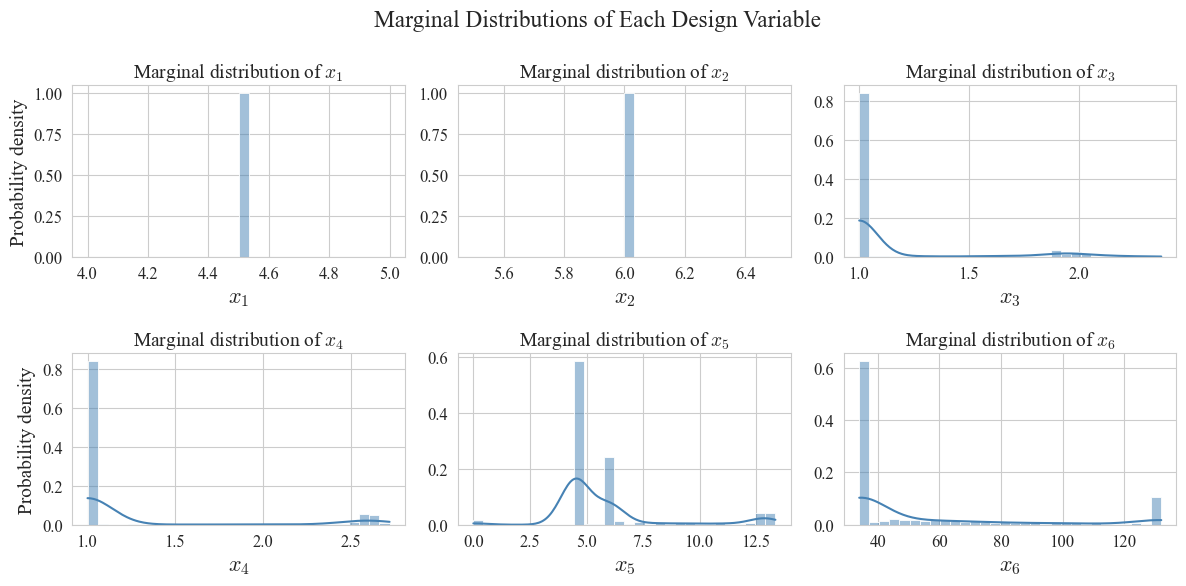

In [13]:
# Figure 9: Marginal distributions of each decision variable for the continuous optimal deci-sion distribution.
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes = axes.flatten()
var_names_for_title = [r"$x_1$", r"$x_2$", r"$x_3$", r"$x_4$", r"$x_5$", r"$x_6$"]
for i in range(6):
    ax = axes[i]
    sns.histplot(X[:, i], stat="probability", bins=30, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Marginal distribution of {var_names_for_title[i]}", fontsize=14)
    if i == 0 or i == 3:
        ax.set_ylabel("Probability density")
    else:
        ax.set_ylabel("")
    ax.set_xlabel(var_names_for_title[i], fontsize=16)
    ax.grid(True)
    ax.tick_params(axis='x', labelsize=12)

plt.suptitle("Marginal Distributions of Each Design Variable")
plt.tight_layout(rect=[0, 0, 1, 1])
# plt.show()
plt.savefig("../results/plots/preference_problem3_norm_t_star_dist.png", dpi=600)

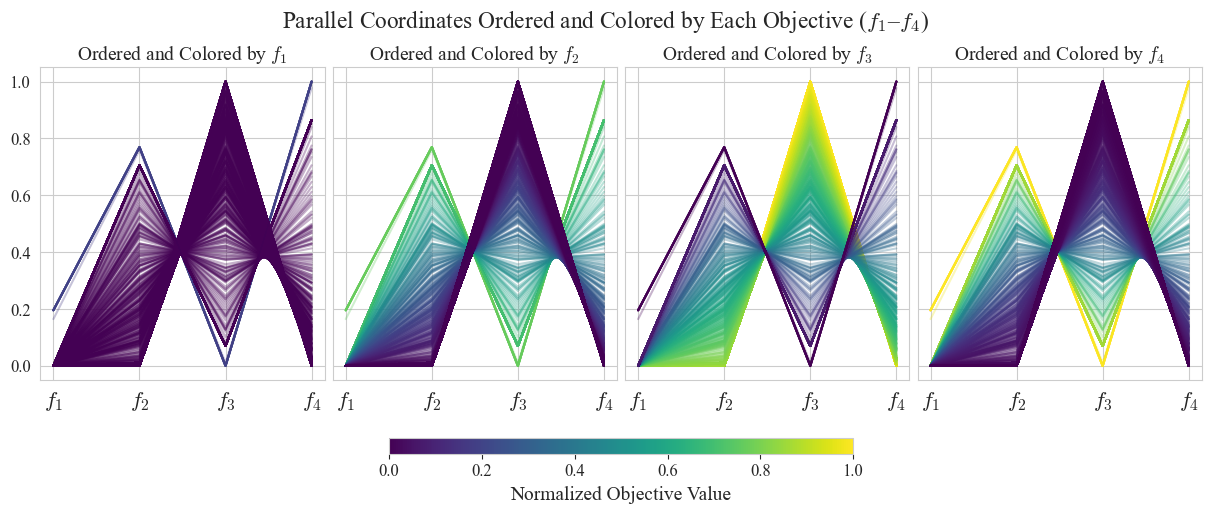

In [14]:
# Figure 10: Parallel coordinates plot of normalized objective values for Pareto-optimal so-lutions in Case Study 2 (continuous distribution).
f_norm = np.array([res['f_norm'] for res in results])
df_continuous_F = pd.DataFrame(f_norm, columns=["f1", "f2", "f3", "f4"])
p = parallel_coordinates_objectives(df_continuous_F)
# p.show()
p.savefig("../results/plots/preference_problem3_norm_parallel_coordinates.png", dpi=600)

[Kernel] S_ij clipped: t=4 (t5), g=0 (g1), S_ij=1.0048 > 1


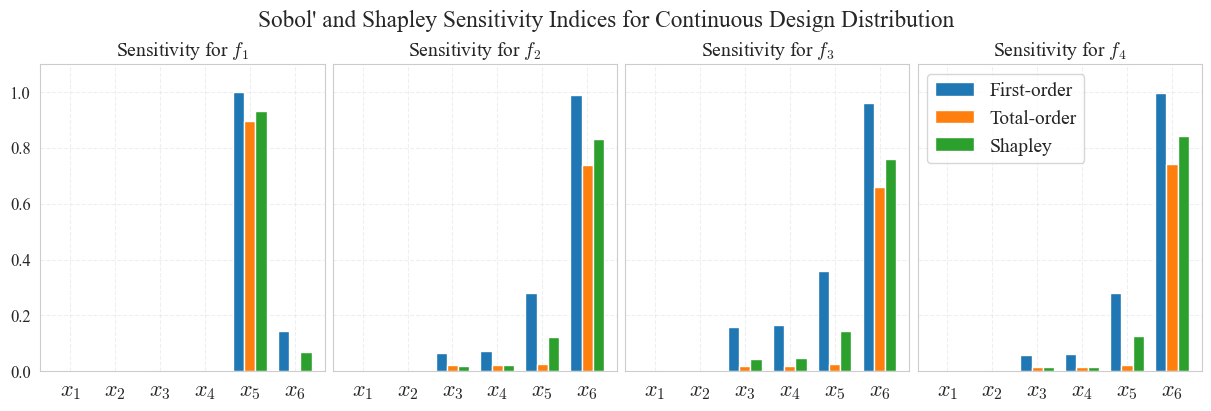

In [15]:
# Figure 11: Sobol' and Shapley sensitivity indices for continuous optimal decision solutions across the four objectives.
bandwidths = silverman_bandwidths(X)
df_sobol_first_continuous = sobol_first_order_kernel(X, f_norm, bandwidth=bandwidths)
df_sobol_total_continuous = sobol_total_order_kernel(X, f_norm, bandwidth=bandwidths)
df_shapley_continuous = shapley_values_kernel(X, f_norm, bandwidth=bandwidths)
# df_sobol_first_continuous, df_sobol_total_continuous, df_shapley_continuous, df_shapley_continuous.sum()
p = histogram_sensitivity(df_sobol_first_continuous, df_sobol_total_continuous, df_shapley_continuous, title="Sobol' and Shapley Sensitivity Indices for Continuous Design Distribution")
# p.show()
p.savefig("../results/plots/preference_problem3_sobol_shapley.png", dpi=600)

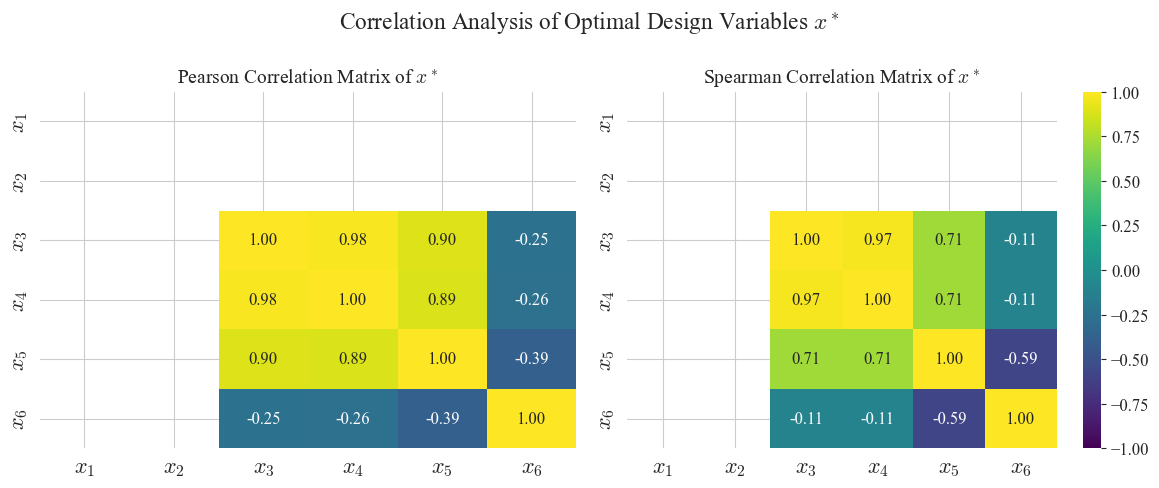

In [16]:
# Figure 12: Pearson and Spearman correlation matrices of the continuous design distribution.
df_continuous = pd.DataFrame(X, columns=[r"$x_1$", r"$x_2$", r"$x_3$", r"$x_4$", r"$x_5$", r"$x_6$"])
corr_pearson = df_continuous.corr()
corr_spearman = df_continuous.corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(corr_pearson, annot=True, fmt=".2f", annot_kws={"size": 12}, cmap="viridis", vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("Pearson Correlation Matrix of $x^*$")
axes[0].tick_params(axis='y', labelsize=16)

sns.heatmap(corr_spearman, annot=True, fmt=".2f", annot_kws={"size": 12}, cmap="viridis", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman Correlation Matrix of $x^*$")
axes[1].tick_params(axis='y', labelsize=16)
plt.suptitle(r"Correlation Analysis of Optimal Design Variables $x^*$")
plt.tight_layout()
# plt.show()
plt.savefig("../results/plots/preference_problem3_norm_t_star_dependence.png", dpi=600)

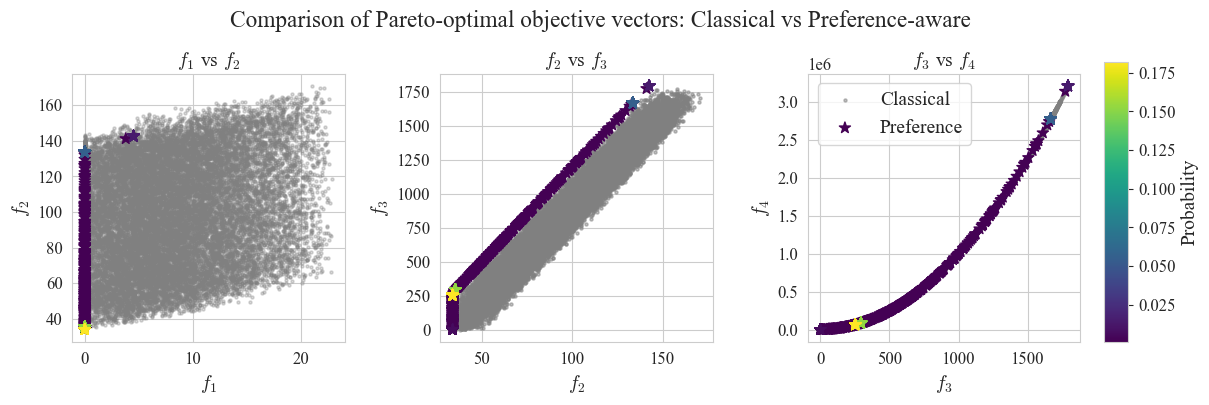

In [17]:
# Figure 13: Classical Pareto-optimal objective vectors (grey) vs. preference-aware solutions (colored by probability mass) for continuous optimal decision.

X, X_vars = generate_hypercube_samples(bounds=problem._bounds, n_samples=100000, exclude_vars=['x7', 'x8'])
X_full, X_vars_full = add_linearization_vars(X, X_vars)
X_dict = [{k: float(v) for k, v in zip(X_vars_full, row)}for row in X_full]
feas_mask = np.array([problem.is_feasible(x) for x in X_dict])
X_dict_feas = [x for x, ok in zip(X_dict, feas_mask) if ok]
obj_names = ["f1", "f2", "f3", "f4"]
F_dict = [problem.evaluate_objectives(x) for x in X_dict_feas]
F_mat  = np.array([[float(d[k]) for k in obj_names] for d in F_dict], dtype=float)

weights = np.array([1.0, 1.0, -1.0, 1.0], dtype=float)
nds = NonDominatedSorting()
pareto_idx = nds.do(F_mat * weights, only_non_dominated_front=True)

# X_pareto = [X_dict_feas[i] for i in pareto_idx]
F_classical = F_mat[pareto_idx]

p = scatter_preference_vs_classical(F_classical, results)
# p.show()
p.savefig("../results/plots/preference_problem3_comparison_moo_preference.png", dpi=600)

In [18]:
# Table 3: Frechet variance of the continuous optimal decision distribution under different preference settings.

for p in preferences_for_frechet_variance:
    betas = gen_preferences(p[0], p[1], 1000, np.random.default_rng(42))
    results = solve_normalized_problem_over_beta_parallel(solve_beta_weighted_nlp, betas, f_min, f_max)
    X_raw, X_norm = extract_and_normalize_X(results, problem._bounds)
    print(f"{p[2]}: {frechet_variance(X_norm[:, :-2])}")

Baseline: 0.2284708025881171
Low uncertainty: 0.02646790698047172
High uncertainty: 0.31357859230348817
Objective 3 emphasized: 0.10726831923808884
Objective 4 emphasized: 0.18861165228885074
